In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

RAW_DATA_PATH = Path("../data/raw/PS_20174392719_1491204439457_log.csv")

assert RAW_DATA_PATH.exists(), f"Dataset not found at: {RAW_DATA_PATH.resolve()}"

RAW_DATA_PATH.resolve()

WindowsPath('D:/Nexvia-Internship/realtime-financial-fraud-detection/data/raw/PS_20174392719_1491204439457_log.csv')

In [2]:
df = pd.read_csv(RAW_DATA_PATH)

print("Shape:", df.shape)
df.head()

Shape: (6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.64",C1231006815,"170,136.00","160,296.36",M1979787155,0.00,0.00,0,0
1,1,PAYMENT,"1,864.28",C1666544295,"21,249.00","19,384.72",M2044282225,0.00,0.00,0,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,"21,182.00",0.00,1,0
4,1,PAYMENT,"11,668.14",C2048537720,"41,554.00","29,885.86",M1230701703,0.00,0.00,0,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


In [4]:
missing_values = df.isna().sum()
missing_percentage = (missing_values / len(df) * 100).round(4)

pd.DataFrame({
    "missing_count": missing_values,
    "missing_percentage": missing_percentage
})

,missing_count,missing_percentage
step,0,0.00
type,0,0.00
amount,0,0.00
nameOrig,0,0.00
oldbalanceOrg,0,0.00
newbalanceOrig,0,0.00
nameDest,0,0.00
oldbalanceDest,0,0.00
newbalanceDest,0,0.00
isFraud,0,0.00


In [5]:
duplicate_rows = df.duplicated().sum()
print("Exact duplicate rows:", duplicate_rows)

Exact duplicate rows: 0


In [6]:
fraud_counts = df["isFraud"].value_counts().sort_index()
fraud_percentage = df["isFraud"].value_counts(normalize=True).sort_index() * 100

pd.DataFrame({
    "count": fraud_counts,
    "percentage": fraud_percentage
})

,count,percentage
isFraud,,
0,6354407,99.87
1,8213,0.13


In [7]:
fraud_by_type = (
    df.groupby("type")["isFraud"]
    .agg(
        transactions="count",
        fraud_cases="sum",
        fraud_rate_percentage=lambda x: x.mean() * 100,
    )
    .sort_values("fraud_cases", ascending=False)
)

fraud_by_type

,transactions,fraud_cases,fraud_rate_percentage
type,,,
CASH_OUT,2237500,4116,0.18
TRANSFER,532909,4097,0.77
CASH_IN,1399284,0,0.00
DEBIT,41432,0,0.00
PAYMENT,2151495,0,0.00


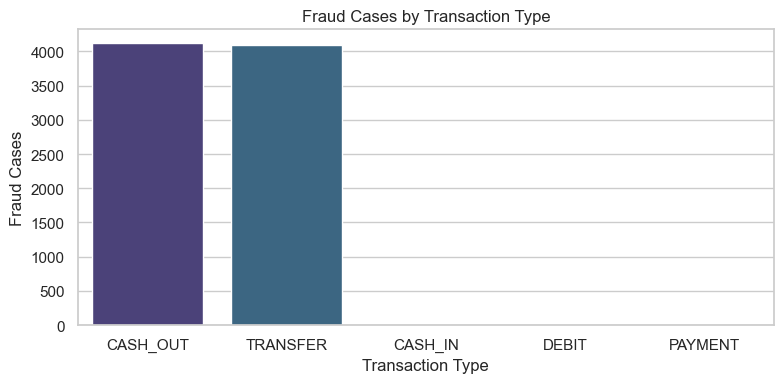

In [8]:
plt.figure(figsize=(8, 4))
sns.barplot(
    data=fraud_by_type.reset_index(),
    x="type",
    y="fraud_cases",
    hue="type",
    palette="viridis",
    legend=False,
)
plt.title("Fraud Cases by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Cases")
plt.tight_layout()
plt.show()

In [9]:
df["amount"].describe()

count    6,362,620.00
mean       179,861.90
std        603,858.23
min              0.00
25%         13,389.57
50%         74,871.94
75%        208,721.48
max     92,445,516.64
Name: amount, dtype: float64

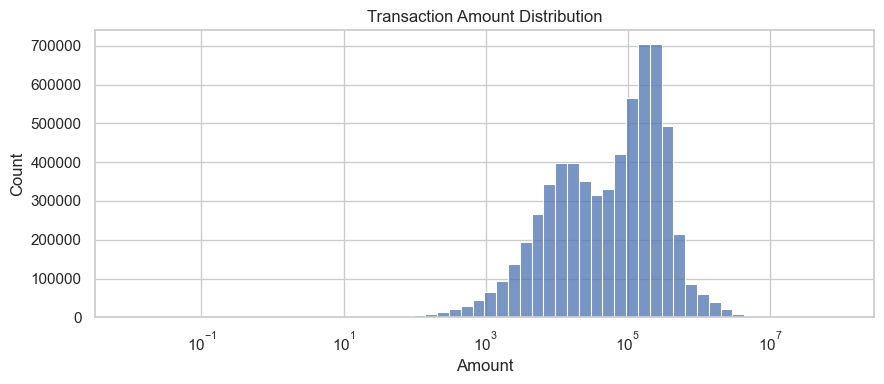

In [10]:
plt.figure(figsize=(9, 4))
sns.histplot(data=df, x="amount", bins=60, log_scale=True)
plt.title("Transaction Amount Distribution")
plt.xlabel("Amount")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

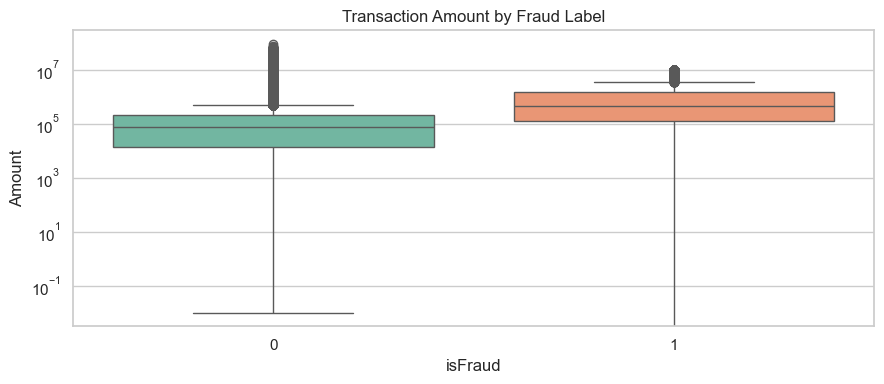

In [11]:
plt.figure(figsize=(9, 4))
sns.boxplot(data=df, x="isFraud", y="amount", hue="isFraud", palette="Set2", legend=False)
plt.yscale("log")
plt.title("Transaction Amount by Fraud Label")
plt.xlabel("isFraud")
plt.ylabel("Amount")
plt.tight_layout()
plt.show()

In [12]:
type_counts = df["type"].value_counts()

type_counts

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

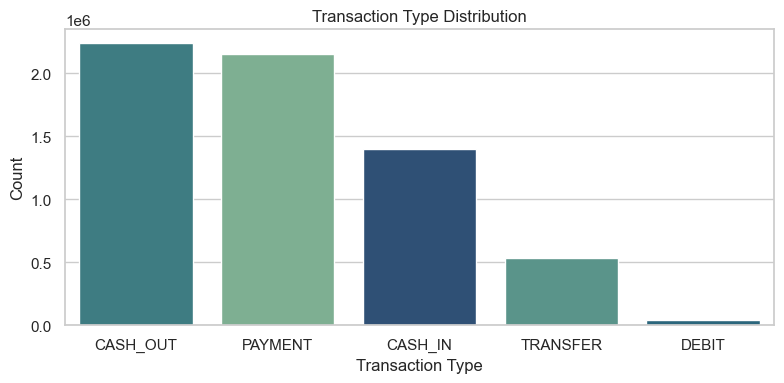

In [13]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="type", hue="type", order=type_counts.index, palette="crest", legend=False)
plt.title("Transaction Type Distribution")
plt.xlabel("Transaction Type")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [14]:
print("Minimum step:", df["step"].min())
print("Maximum step:", df["step"].max())
print("Unique steps:", df["step"].nunique())

Minimum step: 1
Maximum step: 743
Unique steps: 743


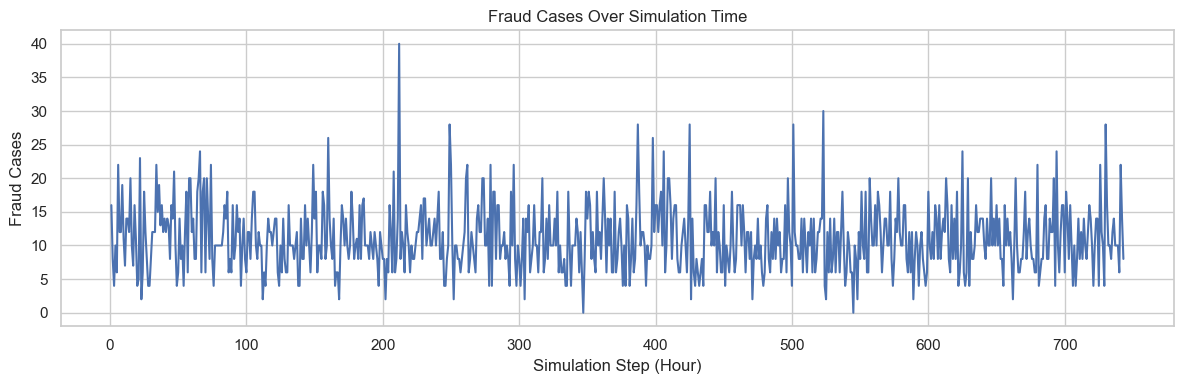

In [15]:
fraud_by_step = df.groupby("step")["isFraud"].sum()

plt.figure(figsize=(12, 4))
fraud_by_step.plot()
plt.title("Fraud Cases Over Simulation Time")
plt.xlabel("Simulation Step (Hour)")
plt.ylabel("Fraud Cases")
plt.tight_layout()
plt.show()

In [16]:
print("Unique sender accounts:", df["nameOrig"].nunique())
print("Unique receiver accounts:", df["nameDest"].nunique())
print("Accounts appearing as both sender and receiver:", len(set(df["nameOrig"]) & set(df["nameDest"])))

Unique sender accounts: 6353307
Unique receiver accounts: 2722362
Accounts appearing as both sender and receiver: 1769


In [17]:
repeat_receivers = df["nameDest"].value_counts()
repeat_receivers.head(10)

nameDest
C1286084959    113
C985934102     109
C665576141     105
C2083562754    102
C248609774     101
C1590550415    101
C1789550256     99
C451111351      99
C1360767589     98
C1023714065     97
Name: count, dtype: int64

In [18]:
sender_balance_change = df["newbalanceOrig"] - df["oldbalanceOrg"]
receiver_balance_change = df["newbalanceDest"] - df["oldbalanceDest"]

pd.DataFrame({
    "sender_balance_change": sender_balance_change.describe(),
    "receiver_balance_change": receiver_balance_change.describe(),
})

,sender_balance_change,receiver_balance_change
count,"6,362,620.00","6,362,620.00"
mean,"21,230.56","124,294.73"
std,"146,643.29","812,939.08"
min,"-10,000,000.00","-13,060,826.21"
25%,"-10,150.44",0.00
50%,0.00,0.00
75%,0.00,"149,105.43"
max,"1,915,267.90","105,687,838.82"


In [19]:
unexpected_sender_change = (sender_balance_change != -df["amount"]).sum()
unexpected_receiver_change = (receiver_balance_change != df["amount"]).sum()

print("Rows where sender balance change does not equal -amount:", unexpected_sender_change)
print("Rows where receiver balance change does not equal amount:", unexpected_receiver_change)

Rows where sender balance change does not equal -amount: 5922109
Rows where receiver balance change does not equal amount: 5602260


In [20]:
from IPython.display import Markdown, display

fraud_total = int(fraud_counts.get(1, 0))
fraud_prevalence = fraud_total / len(df) * 100
cash_out_share = fraud_by_type.loc["CASH_OUT", "fraud_cases"] / fraud_total * 100
transfer_share = fraud_by_type.loc["TRANSFER", "fraud_cases"] / fraud_total * 100

sender_accounts = set(df["nameOrig"])
receiver_accounts = set(df["nameDest"])
account_overlap = len(sender_accounts & receiver_accounts)

amount_median = df["amount"].median()
amount_99th = df["amount"].quantile(0.99)
amount_max = df["amount"].max()

summary = f"""
## EDA Summary

- **Dataset shape:** {df.shape[0]:,} rows and {df.shape[1]} columns
- **Missing values:** {int(missing_values.sum()):,} missing values
- **Exact duplicate rows:** {duplicate_rows:,}
- **Fraud prevalence:** {fraud_total:,} fraudulent transactions ({fraud_prevalence:.2f}%)
- **Fraud concentration by transaction type:** CASH_OUT accounts for {cash_out_share:.2f}% and TRANSFER for {transfer_share:.2f}% of all fraud cases; no fraud was observed in CASH_IN, DEBIT, or PAYMENT.
- **Amount distribution observation:** Transaction amounts are strongly right-skewed; the median is ${amount_median:,.2f}, the 99th percentile is ${amount_99th:,.2f}, and the maximum is ${amount_max:,.2f}.
- **Time range:** Simulation steps range from {df["step"].min()} to {df["step"].max()} ({df["step"].nunique()} unique steps).
- **Account relationship observation:** {account_overlap:,} accounts appear as both senders and receivers, while receiver activity is highly concentrated among a small number of accounts.
- **Balance consistency observation:** Balance changes frequently do not reconcile exactly with transaction amounts, indicating zero-balance behavior, incomplete balance updates, or dataset-specific accounting patterns.
- **Modeling implications:** The extreme class imbalance requires stratified evaluation and imbalance-aware methods. Transaction type, amount, balance features, account activity, and time should be engineered carefully, with temporal validation used to reduce leakage.
"""

display(Markdown(summary))


## EDA Summary

- **Dataset shape:** 6,362,620 rows and 11 columns
- **Missing values:** 0 missing values
- **Exact duplicate rows:** 0
- **Fraud prevalence:** 8,213 fraudulent transactions (0.13%)
- **Fraud concentration by transaction type:** CASH_OUT accounts for 50.12% and TRANSFER for 49.88% of all fraud cases; no fraud was observed in CASH_IN, DEBIT, or PAYMENT.
- **Amount distribution observation:** Transaction amounts are strongly right-skewed; the median is $74,871.94, the 99th percentile is $1,615,979.47, and the maximum is $92,445,516.64.
- **Time range:** Simulation steps range from 1 to 743 (743 unique steps).
- **Account relationship observation:** 1,769 accounts appear as both senders and receivers, while receiver activity is highly concentrated among a small number of accounts.
- **Balance consistency observation:** Balance changes frequently do not reconcile exactly with transaction amounts, indicating zero-balance behavior, incomplete balance updates, or dataset-specific accounting patterns.
- **Modeling implications:** The extreme class imbalance requires stratified evaluation and imbalance-aware methods. Transaction type, amount, balance features, account activity, and time should be engineered carefully, with temporal validation used to reduce leakage.
